# Spike #14 — Trouve-t-on des séries de prix publiques pour la pistache, le matcha et le cacao ?

**Question** : existe-t-il des séries de prix publiques et exploitables pour la pistache, le matcha et le cacao de 2020 à 2025 ?
**Méthode** : recherche dans Banque mondiale (Pink Sheet), FAO, ICCO, USDA, BLS ; format, fréquence, licence.
**Seuil** : 3 séries mensuelles exploitables sur 2020-2025. **Durée max** : ½ jour.

Collecte du 12/11/2026 via FRED (Federal Reserve Bank of St. Louis), qui republie les séries officielles. Fichiers bruts dans `raw/prix/`.

## Inventaire des sources examinées

| Matière | Source | Série | Fréquence | Licence / accès | Verdict |
|---|---|---|---|---|---|
| Cacao | FMI, *Primary Commodity Prices*, via FRED `PCOCOUSDM` | Prix mondial du cacao, USD/tonne | Mensuelle, 1990 → 09/2026 | Données publiques, citation de la source | **Exploitable** |
| Cacao | Banque mondiale, *Pink Sheet* (CMO historical data) | Cocoa, USD/kg | Mensuelle | CC BY 4.0 | Exploitable (source de recoupement) |
| Cacao | ICCO | Prix quotidien ICCO | Quotidienne / mensuelle | Statistiques détaillées payantes | Non retenue |
| Pistache | BLS, indice des prix à la production, via FRED `WPU01190106` | *Farm Products: Pistachios*, indice déc. 1991 = 100 | Mensuelle, 1991 → 09/2026 | Domaine public (gouvernement US) | **Partielle** (voir §2) |
| Pistache | USDA ERS, *Fruit and Tree Nuts Data* | Prix producteur US | Annuelle (campagne) | Domaine public | Non mensuelle |
| Pistache | Banque mondiale / FMI | — | — | — | Aucune série pistache |
| Matcha | Banque mondiale, FMI, FAO | — | — | — | **Aucune série matcha ni thé vert japonais** (le thé du Pink Sheet est du thé noir, enchères Mombasa / Colombo / Kolkata) |
| Matcha | Douanes japonaises, statistiques du commerce, code SH 0902.10-100 (thé vert en poudre, emballages ≤ 3 kg) | Valeur et quantité exportées → valeur unitaire (¥/kg) | Mensuelle | Statistiques publiques japonaises | **Proxy possible, non récupéré** dans le temps imparti |
| Matcha | Enchères de tencha (Kyoto, Kagoshima), presse | Prix au kg | Annuelle, articles de presse | Droits de presse | Preuve documentaire seulement |

In [1]:
import pandas as pd, matplotlib.pyplot as plt, json
def fred(id_):
    d = pd.read_csv(f"raw/prix/fred_{id_}.csv")
    d.columns = ["date", "valeur"]
    d["date"] = pd.to_datetime(d["date"]); d["valeur"] = pd.to_numeric(d["valeur"], errors="coerce")
    return d.set_index("date")["valeur"]
cacao, pistache = fred("PCOCOUSDM"), fred("WPU01190106")
p = slice("2020-01-01", "2025-12-01")
pd.DataFrame({"cacao_USD_t": cacao[p], "pistache_indice": pistache[p]}).describe().round(1)

,cacao_USD_t,pistache_indice
count,72.0,72.0
mean,4267.0,251.4
std,2565.5,34.2
min,2102.1,214.3
25%,2380.3,214.3
50%,2594.8,257.2
75%,6462.1,272.8
max,10710.3,319.9


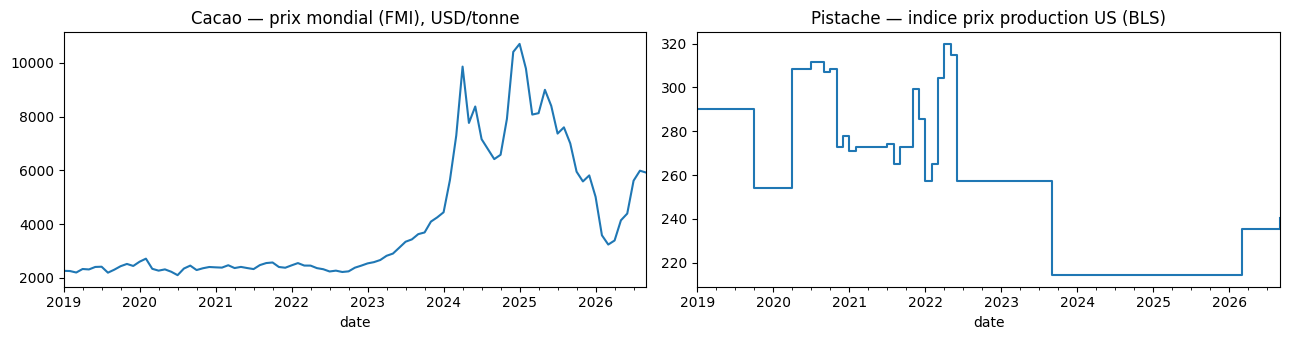

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
cacao["2019":].plot(ax=ax[0], title="Cacao — prix mondial (FMI), USD/tonne")
pistache["2019":].plot(ax=ax[1], title="Pistache — indice prix production US (BLS)", drawstyle="steps-post")
plt.tight_layout(); plt.show()

## 2. Contrôle : la série est-elle vraiment mensuelle ?
Une série peut être publiée chaque mois en recopiant la même valeur. On compte les mois où la valeur change.

In [3]:
def controle(s, nom):
    x = s[p].dropna()
    changements = int((x.diff().fillna(1) != 0).sum())
    plus_long_plateau = int(x.groupby((x != x.shift()).cumsum()).size().max())
    return {"serie": nom, "mois_2020_2025": len(x), "mois_ou_la_valeur_change": changements,
            "plus_long_plateau_mois": plus_long_plateau, "manquants": int(s[p].isna().sum())}
pd.DataFrame([controle(cacao, "cacao (FMI)"), controle(pistache, "pistache (BLS PPI)")])

,serie,mois_2020_2025,mois_ou_la_valeur_change,plus_long_plateau_mois,manquants
0,cacao (FMI),72,72,1,0
1,pistache (BLS PPI),72,21,28,0


## Décision

**Seuil non atteint : 1 série pleinement exploitable sur 3 attendues.**

- **Cacao : GO.** Série mensuelle complète 2020-2025 (FMI via FRED), recoupable avec le Pink Sheet de la Banque mondiale (CC BY 4.0). Elle montre l'envolée des prix de 2024.
- **Pistache : partiel.** L'indice BLS est publié chaque mois, mais la valeur reste figée pendant de longues périodes (voir le contrôle ci-dessus). Il donne la direction des prix aux États-Unis, pas un vrai suivi mensuel. On l'utilise avec le drapeau `serie_peu_reactive`, pour la composante « matière » du score seulement en tendance annuelle.
- **Matcha : NO-GO en série de prix.** Aucune source publique de prix mensuel. Le meilleur proxy est la valeur unitaire des exportations japonaises de thé vert en poudre (douanes, SH 0902.10-100), à récupérer en semaine 2. D'ici là, la composante « matière » du matcha reste documentaire : articles datés sur la hausse du tencha, avec sources, sans chiffre inventé.

**Conséquence pour l'écran Verdict** : la variation du prix sur 12 mois n'est affichée que pour le cacao. Pour la pistache, on affiche « tendance indicative ». Pour le matcha, « pas de série de prix publique ; sources documentaires ».

## Sources
- FRED, *Global price of Cocoa* (PCOCOUSDM), source FMI : https://fred.stlouisfed.org/series/PCOCOUSDM
- FRED, *PPI by Commodity: Farm Products: Pistachios* (WPU01190106), source BLS : https://fred.stlouisfed.org/series/WPU01190106
- Banque mondiale, *Commodity Markets (Pink Sheet)* : https://www.worldbank.org/en/research/commodity-markets
- USDA ERS, *Fruit and Tree Nuts Data* : https://www.ers.usda.gov/data-products/fruit-and-tree-nuts-data
- Japan Customs / kanzei.or.jp, SH 0902.10-100 : https://www.kanzei.or.jp/statistical/expstatis/detail/index/e/090210100